# REAL-CV-1. Определение ключевых точек и каркаса человека

**Спринт I · Skillfactory · виртуальный коуч**

Цель: выполнить девять шагов задания — загрузить предобученную Keypoint R-CNN,
найти опорные точки на фотографии бегущей девушки и отрисовать её скелет.
Обучение модели в этом задании не требуется.

**Исходные материалы:**
`dspr_cv_u1_diploma_spr1_3_1.png` из папки проекта.
Ниже сохранены результаты реального запуска модели на этом изображении.

## Запуск в составе проекта

Это сохранённый учебный этап. Основной пример финальной версии находится в `examples/01_video_comparison.ipynb`.

## Подготовка: импорты и параметры

`CONF_THRESHOLD` отбирает людей, `KEYPOINT_THRESHOLD` — отдельные опорные точки.
Оставим значения из задания: **0.9** и **2.0**. Оценка ключевой точки
`keypoints_scores` не является вероятностью: значение может быть больше единицы.
Третий элемент `keypoints[..., 2]` не используем вместо этой оценки.

In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import platform

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from PIL import Image, ImageOps
from IPython.display import Markdown, display
from torchvision import transforms as T
from torchvision.models.detection import (
    KeypointRCNN_ResNet50_FPN_Weights,
    keypointrcnn_resnet50_fpn,
)

%matplotlib inline
plt.rcParams.update({
    "figure.figsize": (12, 8),
    "figure.dpi": 110,
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 15,
})

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "REAL_CV_1_Keypoint_RCNN.ipynb").is_file():
    PROJECT_DIR = PROJECT_DIR / "examples" / "sprints" / "sprint_1"
IMAGE_PATH = PROJECT_DIR / "dspr_cv_u1_diploma_spr1_3_1.png"
OUTPUT_DIR = PROJECT_DIR / "outputs"
CONF_THRESHOLD = 0.9
KEYPOINT_THRESHOLD = 2.0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
torch.backends.cudnn.benchmark = False

if not IMAGE_PATH.is_file():
    raise FileNotFoundError(
        f"Не найдено изображение: {IMAGE_PATH}. "
        "Укажите папку с изображением в PROJECT_DIR."
    )
OUTPUT_DIR.mkdir(exist_ok=True)

versions = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "opencv": cv2.__version__,
}
print("Версии:", versions)
print("Устройство:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Версии: {'python': '3.11.7', 'torch': '2.5.1+cu121', 'torchvision': '0.20.1+cu121', 'numpy': '2.4.6', 'matplotlib': '3.11.1', 'opencv': '4.11.0'}
Устройство: cuda
GPU: NVIDIA GeForce RTX 4070 Ti


## 1. Загрузка предобученной сети

Используем `torchvision.models.detection.keypointrcnn_resnet50_fpn` с весами
`COCO_V1` (в используемой версии это также `DEFAULT`). Явное имя весов
фиксирует выбранную модель. `eval()` переключает её в режим предсказания.

Модель принимает список RGB-тензоров вида `[3, H, W]` со значениями от 0 до 1.

In [2]:
weights = KeypointRCNN_ResNet50_FPN_Weights.COCO_V1
model = keypointrcnn_resnet50_fpn(weights=weights, progress=False)
model = model.to(DEVICE)
model.eval()
print("Модель:", model.__class__.__name__)
print("Веса:", weights.name)
print("Режим обучения:", model.training)

Модель: KeypointRCNN
Веса: COCO_V1
Режим обучения: False


## 2. Список опорных точек

Порядок 17 точек соответствует COCO и выходу модели. `left` и `right`
обозначают стороны тела человека, а не левую и правую стороны изображения.

In [3]:
keypoints = [
    "nose", "left_eye", "right_eye", "left_ear", "right_ear",
    "left_shoulder", "right_shoulder", "left_elbow", "right_elbow",
    "left_wrist", "right_wrist", "left_hip", "right_hip",
    "left_knee", "right_knee", "left_ankle", "right_ankle",
]
assert keypoints == weights.meta["keypoint_names"]
print(f"Опорных точек: {len(keypoints)}")

Опорных точек: 17


## 3. Загрузка изображения и трансформации

Читаем фотографию через Pillow, учитываем ориентацию EXIF и переводим её в RGB.
Затем применяем `T.Compose([T.ToTensor()])`, как требуется в задании.
Дополнительная нормализация не нужна: она выполняется внутри модели.
Исходное разрешение сохраняется для отрисовки.

Размер изображения: 1300 × 886 пикселей
Форма тензора: (3, 886, 1300)


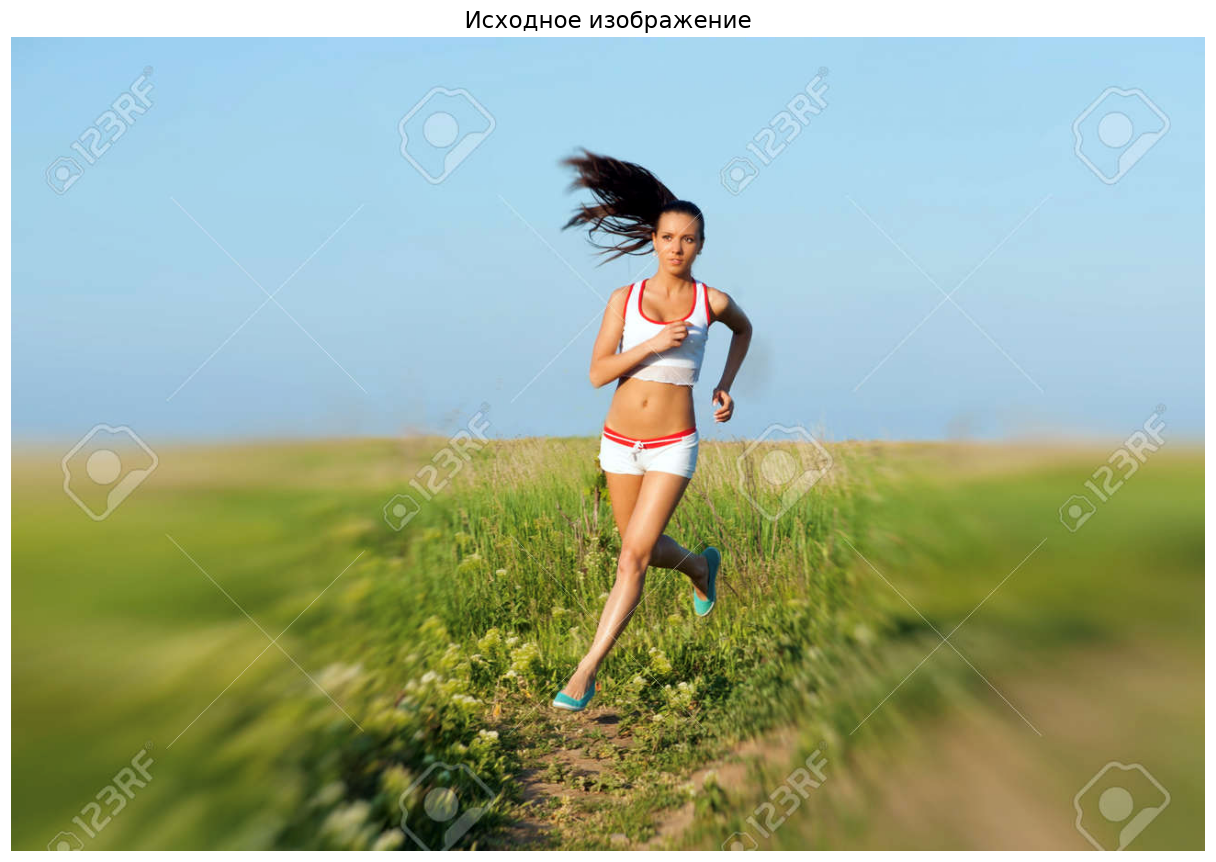

In [4]:
with Image.open(IMAGE_PATH) as source:
    pil_image = ImageOps.exif_transpose(source).convert("RGB")
image_rgb = np.array(pil_image)
transform = T.Compose([T.ToTensor()])
image_tensor = transform(pil_image)

assert image_tensor.ndim == 3 and image_tensor.shape[0] == 3
assert image_tensor.dtype == torch.float32
assert 0.0 <= image_tensor.min().item() <= image_tensor.max().item() <= 1.0
print(f"Размер изображения: {pil_image.width} × {pil_image.height} пикселей")
print("Форма тензора:", tuple(image_tensor.shape))

fig, ax = plt.subplots()
ax.imshow(image_rgb)
ax.set_title("Исходное изображение")
ax.axis("off")
fig.tight_layout()
plt.show()

## 4. Получение ключевых точек

`torch.inference_mode()` отключает расчёт градиентов. После инференса переносим
результат на CPU, чтобы использовать его с NumPy и OpenCV.
Координаты возвращаются в пикселях исходного изображения: начало координат
слева сверху, `x` направлена вправо, `y` — вниз.

Для отрисовки нужны `scores` (оценки детекций), `keypoints` (координаты)
и `keypoints_scores` (оценки отдельных точек). Последнее поле содержит
значения из тепловых карт; в установленной версии это видно в
[исходном коде Torchvision](https://github.com/pytorch/vision/blob/v0.20.1/torchvision/models/detection/roi_heads.py).

In [5]:
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
started = perf_counter()
with torch.inference_mode():
    prediction = model([image_tensor.to(DEVICE)])[0]
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
inference_seconds = perf_counter() - started

prediction = {name: tensor.detach().cpu() for name, tensor in prediction.items()}
all_keypoints = prediction["keypoints"]
all_scores = prediction["keypoints_scores"]
confs = prediction["scores"]

assert all_keypoints.shape == (len(confs), len(keypoints), 3)
assert all_scores.shape == (len(confs), len(keypoints))
assert torch.isfinite(all_keypoints).all() and torch.isfinite(all_scores).all()

person_ids = torch.where(confs > CONF_THRESHOLD)[0].tolist()
print(f"Инференс одного изображения: {inference_seconds:.2f} с")
print(f"Детекций до порога: {len(confs)}; после порога: {len(person_ids)}")
for person_id in person_ids:
    visible_count = int((all_scores[person_id] > KEYPOINT_THRESHOLD).sum())
    print(f"Человек {person_id}: score={confs[person_id]:.4f}; "
          f"точек выше порога: {visible_count}/{len(keypoints)}")
if not person_ids:
    print("Ни один человек не прошёл порог. Уменьшите CONF_THRESHOLD и повторите отрисовку.")

Инференс одного изображения: 0.54 с
Детекций до порога: 2; после порога: 1
Человек 0: score=0.9997; точек выше порога: 17/17


## 5. Отрисовка ключевых точек

Сохраняем логику и интерфейс функции из задания. Добавлены обработка пустого
результата и безопасный перевод тензоров с GPU на CPU. Цвета выбираются через
`linspace`, поэтому нет деления на ноль и ограничения на число людей.
Изображение и цвета здесь остаются в **RGB**; OpenCV записывает переданные
значения каналов непосредственно в массив.

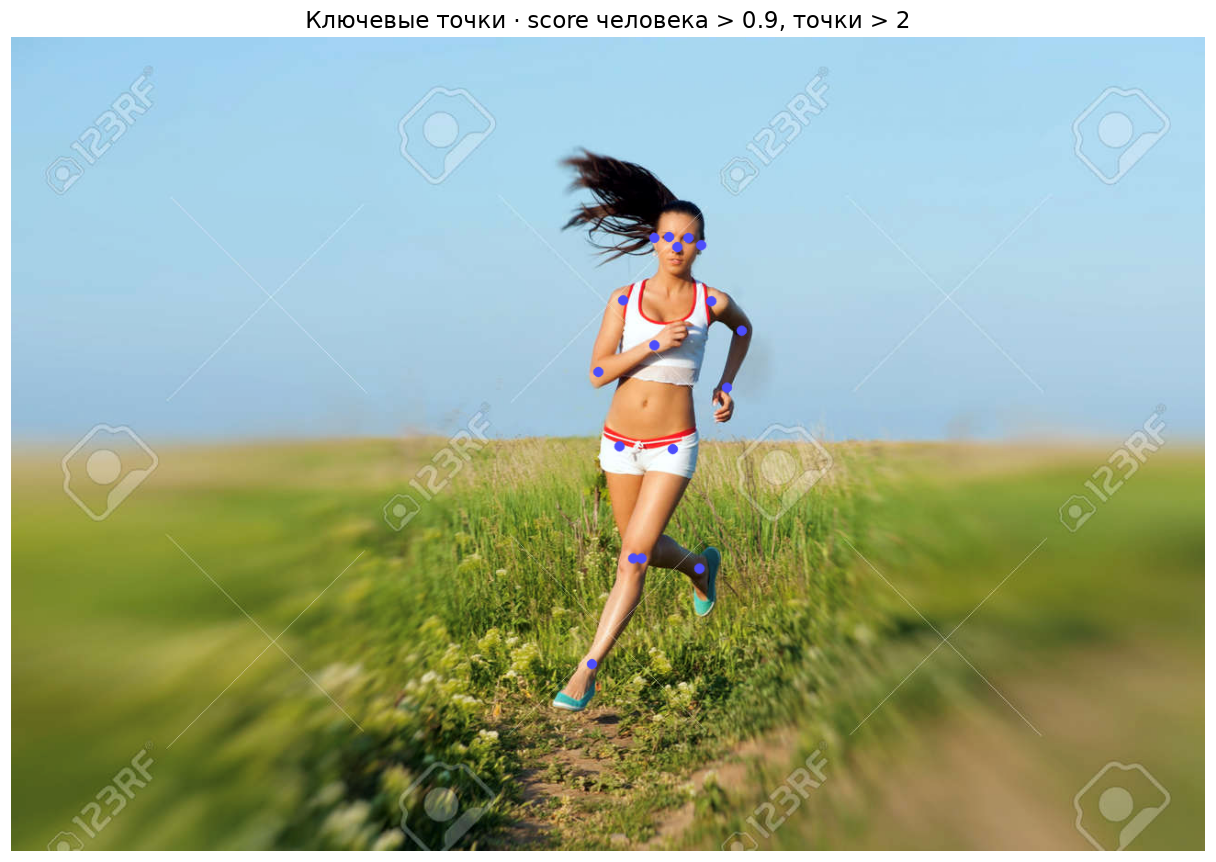

In [6]:
def to_numpy(value):
    """Принимает тензор на CPU/GPU или массив NumPy."""
    if isinstance(value, torch.Tensor):
        return value.detach().cpu().numpy()
    return np.asarray(value)


def person_colors(count):
    """Один RGB-цвет для каждого человека, общий для точек и линий."""
    cmap = plt.get_cmap("rainbow")
    return [
        tuple(int(channel * 255) for channel in cmap(position)[:3])
        for position in np.linspace(0.1, 0.9, count)
    ]


def draw_keypoints_per_person(
    img, all_keypoints, all_scores, confs,
    keypoint_threshold=2, conf_threshold=0.9,
):
    """Рисует точки людей, прошедших оба порога; исходный RGB-массив не меняет."""
    img_copy = img.copy()
    points = to_numpy(all_keypoints)
    point_scores = to_numpy(all_scores)
    person_scores = to_numpy(confs)
    colors = person_colors(len(points))

    for person_id, person_points in enumerate(points):
        if person_scores[person_id] <= conf_threshold:
            continue
        for point, score in zip(person_points, point_scores[person_id]):
            if score > keypoint_threshold and np.isfinite(point[:2]).all():
                position = tuple(np.rint(point[:2]).astype(int).tolist())
                cv2.circle(img_copy, position, 5, colors[person_id], -1,
                           lineType=cv2.LINE_AA)
    return img_copy


keypoints_image = draw_keypoints_per_person(
    image_rgb, all_keypoints, all_scores, confs,
    keypoint_threshold=KEYPOINT_THRESHOLD,
    conf_threshold=CONF_THRESHOLD,
)
fig, ax = plt.subplots()
ax.imshow(keypoints_image)
ax.set_title(f"Ключевые точки · score человека > {CONF_THRESHOLD}, точки > {KEYPOINT_THRESHOLD:g}")
ax.axis("off")
fig.tight_layout()
plt.show()

## 6. Список связей между точками

Воспроизводим 16 соединений из задания. Каждая пара задаёт индексы двух точек,
между которыми нужно провести линию.

In [7]:
def get_limbs_from_keypoints(keypoints):
    limbs = [
        [keypoints.index("right_eye"), keypoints.index("nose")],
        [keypoints.index("right_eye"), keypoints.index("right_ear")],
        [keypoints.index("left_eye"), keypoints.index("nose")],
        [keypoints.index("left_eye"), keypoints.index("left_ear")],
        [keypoints.index("right_shoulder"), keypoints.index("right_elbow")],
        [keypoints.index("right_elbow"), keypoints.index("right_wrist")],
        [keypoints.index("left_shoulder"), keypoints.index("left_elbow")],
        [keypoints.index("left_elbow"), keypoints.index("left_wrist")],
        [keypoints.index("right_hip"), keypoints.index("right_knee")],
        [keypoints.index("right_knee"), keypoints.index("right_ankle")],
        [keypoints.index("left_hip"), keypoints.index("left_knee")],
        [keypoints.index("left_knee"), keypoints.index("left_ankle")],
        [keypoints.index("right_shoulder"), keypoints.index("left_shoulder")],
        [keypoints.index("right_hip"), keypoints.index("left_hip")],
        [keypoints.index("right_shoulder"), keypoints.index("right_hip")],
        [keypoints.index("left_shoulder"), keypoints.index("left_hip")],
    ]
    return limbs


limbs = get_limbs_from_keypoints(keypoints)
assert len(limbs) == 16
assert all(0 <= index < len(keypoints) for pair in limbs for index in pair)
print(f"Связей в каркасе: {len(limbs)}")

Связей в каркасе: 16


## 7. Функция отрисовки скелета

Линия рисуется, только если человек прошёл `conf_threshold`, а **обе** конечные
точки прошли `keypoint_threshold`. Поверх линий вызывается готовая функция
отрисовки точек: это делает суставы заметнее. Для другого кадра можно использовать
те же функции без изменений.

In [8]:
def draw_skeleton_per_person(
    img, all_keypoints, all_scores, confs, limbs,
    keypoint_threshold=2, conf_threshold=0.9,
):
    """Соединяет надёжные точки и возвращает новое RGB-изображение."""
    img_copy = img.copy()
    points = to_numpy(all_keypoints)
    point_scores = to_numpy(all_scores)
    person_scores = to_numpy(confs)
    colors = person_colors(len(points))

    for person_id, person_points in enumerate(points):
        if person_scores[person_id] <= conf_threshold:
            continue
        for start_id, end_id in limbs:
            if not (
                point_scores[person_id, start_id] > keypoint_threshold
                and point_scores[person_id, end_id] > keypoint_threshold
            ):
                continue
            endpoints = person_points[[start_id, end_id], :2]
            if not np.isfinite(endpoints).all():
                continue
            start, end = [tuple(np.rint(point).astype(int).tolist()) for point in endpoints]
            cv2.line(img_copy, start, end, colors[person_id], 3,
                     lineType=cv2.LINE_AA)

    return draw_keypoints_per_person(
        img_copy, points, point_scores, person_scores,
        keypoint_threshold=keypoint_threshold,
        conf_threshold=conf_threshold,
    )

## 8. Отрисовка каркаса

Слева — исходная фотография, справа — скелет с теми же координатами и масштабом.
Порог фильтрует ненадёжные точки и связи; он не гарантирует анатомическую точность.

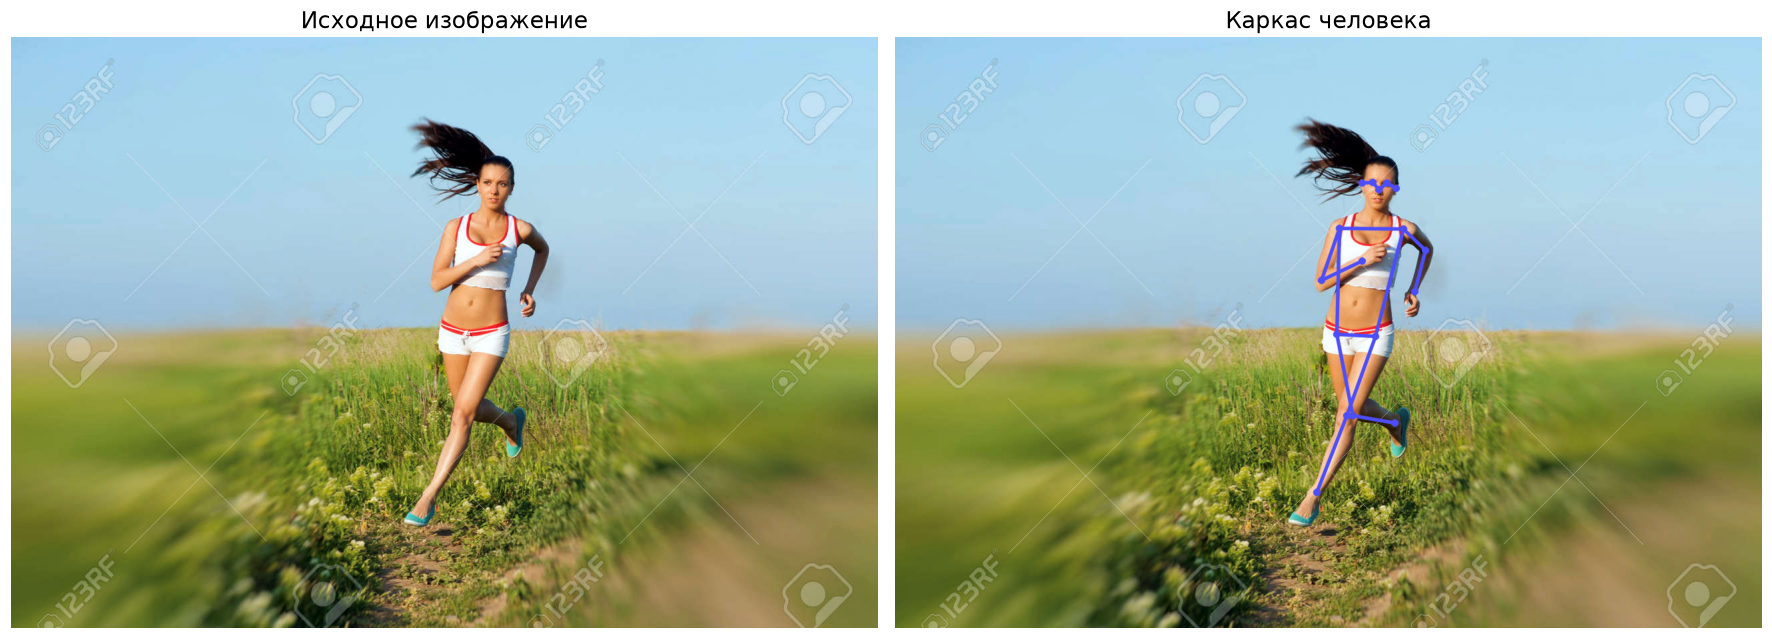

In [9]:
skeleton_image = draw_skeleton_per_person(
    image_rgb, all_keypoints, all_scores, confs, limbs,
    keypoint_threshold=KEYPOINT_THRESHOLD,
    conf_threshold=CONF_THRESHOLD,
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
for ax, image, title in zip(
    axes, [image_rgb, skeleton_image], ["Исходное изображение", "Каркас человека"],
):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
fig.savefig(OUTPUT_DIR / "runner_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### Проверка полученных координат

Таблица ниже содержит все 17 точек для человека с наибольшим `score`, прошедшего
порог. Координаты указаны в пикселях; «нет» в последнем столбце означает,
что точка исключена из рисунка. Это предсказания модели, а не ручная разметка.

In [10]:
if person_ids:
    best_person_id = max(person_ids, key=lambda i: confs[i].item())
    rows = ["| Точка | x, px | y, px | Score точки | На рисунке |",
            "| :--- | ---: | ---: | ---: | :---: |"]
    for point_id, name in enumerate(keypoints):
        x, y = all_keypoints[best_person_id, point_id, :2].tolist()
        score = all_scores[best_person_id, point_id].item()
        shown = "да" if score > KEYPOINT_THRESHOLD else "нет"
        rows.append(f"| {name} | {x:.1f} | {y:.1f} | {score:.2f} | {shown} |")
    display(Markdown("\n".join(rows)))
else:
    print("Таблица не построена: нет людей выше порога.")

# Проверяем граничный случай, который ломал пример функции из задания.
empty_skeleton = draw_skeleton_per_person(
    image_rgb, all_keypoints[:0], all_scores[:0], confs[:0], limbs,
)
assert np.array_equal(empty_skeleton, image_rgb)
assert np.array_equal(image_rgb, np.array(pil_image)), "Исходное изображение изменилось"
assert skeleton_image.shape == image_rgb.shape and skeleton_image.dtype == np.uint8
print("Проверки размеров, сохранности исходника и пустого результата пройдены.")

| Точка | x, px | y, px | Score точки | На рисунке |
| :--- | ---: | ---: | ---: | :---: |
| nose | 724.6 | 228.4 | 15.77 | да |
| left_eye | 736.7 | 218.4 | 14.49 | да |
| right_eye | 715.7 | 217.3 | 16.60 | да |
| left_ear | 751.1 | 226.2 | 12.04 | да |
| right_ear | 700.2 | 218.4 | 15.82 | да |
| left_shoulder | 762.2 | 287.1 | 8.19 | да |
| right_shoulder | 665.9 | 286.0 | 11.08 | да |
| left_elbow | 795.3 | 319.2 | 7.85 | да |
| right_elbow | 639.4 | 363.5 | 12.02 | да |
| left_wrist | 778.8 | 381.2 | 9.62 | да |
| right_wrist | 700.2 | 334.7 | 15.97 | да |
| left_hip | 720.1 | 447.7 | 13.38 | да |
| right_hip | 661.5 | 445.5 | 13.30 | да |
| left_knee | 677.0 | 567.3 | 16.50 | да |
| right_knee | 685.8 | 567.3 | 6.92 | да |
| left_ankle | 631.6 | 682.4 | 7.71 | да |
| right_ankle | 748.9 | 578.3 | 8.23 | да |

Проверки размеров, сохранности исходника и пустого результата пройдены.


## 9. Сохранение результатов и ноутбука

Изображения и предсказания сохраняются в `outputs/`. Файл `runner_predictions.npz`
содержит координаты **всех** детекций до порога, их оценки, имена точек и связи.
Это позволит использовать результат в следующем спринте. Параметры запуска,
версии библиотек и хеш исходного изображения записываются в `runner_run.json`.
Повторный запуск обновляет эти выходные файлы.

Сам ноутбук сохраняйте через **Ctrl+S** в Jupyter или VS Code.

In [11]:
Image.fromarray(keypoints_image).save(OUTPUT_DIR / "runner_keypoints.png")
Image.fromarray(skeleton_image).save(OUTPUT_DIR / "runner_skeleton.png")
np.savez_compressed(
    OUTPUT_DIR / "runner_predictions.npz",
    boxes=prediction["boxes"].numpy(),
    labels=prediction["labels"].numpy(),
    scores=confs.numpy(),
    keypoints=all_keypoints.numpy(),
    keypoints_scores=all_scores.numpy(),
    keypoint_names=np.asarray(keypoints),
    limbs=np.asarray(limbs),
    selected_person_ids=np.asarray(person_ids, dtype=np.int64),
)

run_info = {
    "input_file": IMAGE_PATH.name,
    "input_sha256": hashlib.sha256(IMAGE_PATH.read_bytes()).hexdigest(),
    "image_size_wh": list(pil_image.size),
    "model": "keypointrcnn_resnet50_fpn",
    "weights": weights.name,
    "weights_url": weights.url,
    "device": str(DEVICE),
    "versions": versions,
    "conf_threshold": CONF_THRESHOLD,
    "keypoint_threshold": KEYPOINT_THRESHOLD,
    "detections_before_threshold": len(confs),
    "selected_person_ids": person_ids,
    "inference_seconds": round(inference_seconds, 4),
}
(OUTPUT_DIR / "runner_run.json").write_text(
    json.dumps(run_info, ensure_ascii=False, indent=2), encoding="utf-8",
)
for name in ["runner_keypoints.png", "runner_skeleton.png", "runner_comparison.png",
             "runner_predictions.npz", "runner_run.json"]:
    print("Сохранён:", "outputs/" + name)

Сохранён: outputs/runner_keypoints.png
Сохранён: outputs/runner_skeleton.png
Сохранён: outputs/runner_comparison.png
Сохранён: outputs/runner_predictions.npz
Сохранён: outputs/runner_run.json


## Вывод по запуску

Следующая ячейка формирует итог из фактических предсказаний, поэтому он обновится
при замене изображения или порогов.

In [12]:
summary = [
    f"**Результат:** детекций до фильтрации — {len(confs)}; "
    f"после порога score > {CONF_THRESHOLD} — {len(person_ids)}.",
]
for person_id in person_ids:
    valid_points = all_scores[person_id] > KEYPOINT_THRESHOLD
    drawn_limbs = sum(bool(valid_points[a] and valid_points[b]) for a, b in limbs)
    summary.append(
        f"- Человек {person_id}: score **{confs[person_id]:.4f}**, "
        f"нарисовано **{int(valid_points.sum())}/17 точек** "
        f"и **{drawn_limbs}/{len(limbs)} связей**."
    )
summary.append(
    "\nРеализованы загрузка модели, преобразование изображения, инференс, "
    "отрисовка точек и каркаса, сохранение результатов. Без эталонной разметки "
    "нельзя численно оценить точность позы; высокий score человека не гарантирует "
    "точность каждого сустава. Сравнение с референсной позой относится к следующему спринту."
)
display(Markdown("\n\n".join(summary)))

**Результат:** детекций до фильтрации — 2; после порога score > 0.9 — 1.

- Человек 0: score **0.9997**, нарисовано **17/17 точек** и **16/16 связей**.


Реализованы загрузка модели, преобразование изображения, инференс, отрисовка точек и каркаса, сохранение результатов. Без эталонной разметки нельзя численно оценить точность позы; высокий score человека не гарантирует точность каждого сустава. Сравнение с референсной позой относится к следующему спринту.